In [53]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk3-task2-spills.ipynb")

c:\Users\olivi\.conda\envs\eds220-env\Lib\site-packages\nbformat\validator.py:434: DuplicateCellId: Non-unique cell id '4d52d6d9-e745-43b4-9320-6f54aa03165d' detected. Corrected to '73899889'.
  _validate(nbdict, ref, version, version_minor, relax_add_props)
c:\Users\olivi\.conda\envs\eds220-env\Lib\site-packages\nbformat\validator.py:434: DuplicateCellId: Non-unique cell id 'cb27288e-e39c-424a-a6d9-91246bc5ccb8' detected. Corrected to 'a9d708f8'.
  _validate(nbdict, ref, version, version_minor, relax_add_props)


# Task 2: Visualizing oil spills in NY State

## Instructions

- First, update the following cell to have a link to *your* Homework 3 GitHub repository:

**UPDATE THIS LINK**
https://github.com/gingersknapp/eds220-hwk3


- Review the [complete rubric for this task](https://docs.google.com/document/d/1Ce4EO3MEHW5uLks4x8BECWlkim2bcmxB4f8Qo4z26z8/edit?usp=sharing) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- Comment mindfully in a way that enriches your code. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.


## About the data
In this task you will use two datasets:

### First dataset: oil spills data

The first dataset contains information about [spilling incidents in the state of New York](https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk). Make sure you study the data portal and understand what each row represents before starting to code. 
You will find extra information and metadata for this dataset in the `NYSDEC_SpillIncidents_Overview.pdf` and `NYSDEC_SpillIncidents_DataDictionary.pdf` documents available at the portal.

### Second dataset: TIGER shapefile

The second dataset is the [2026 Counties (and equivalent) TIGER shapefile](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html) (file `tl_2026_us_county.zip`) from the Census Bureau. You can check the [metadata for all the TIGER shapefiles here](https://www.census.gov/programs-surveys/geography/technical-documentation/complete-technical-documentation/tiger-geo-line.html). 

### COMPLETE WORKFLOW
You will use the next code cell to complete the last exercise in the task. Leave it blank for now.

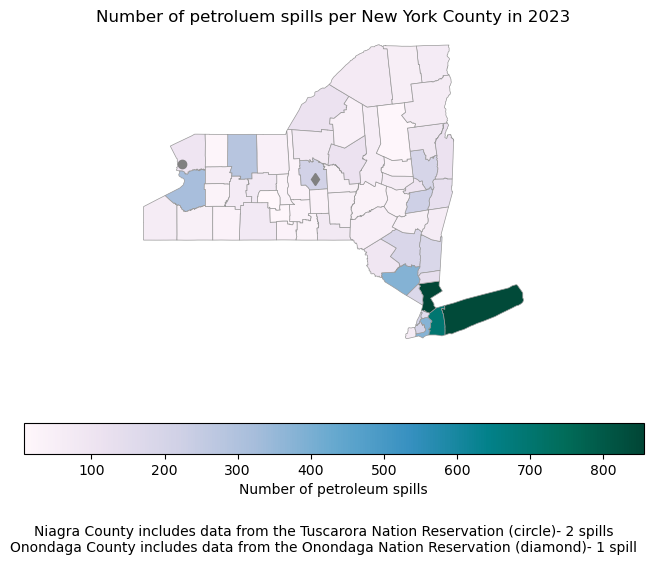

In [54]:
# Import libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

# Load spill event data
spills_fp = os.path.join('data', 'Spill_Incidents_20261103.csv')
spills = pd.read_csv(spills_fp)

# Load county data
county_fp = os.path.join('data', 'tl_2026_us_county', 'tl_2026_us_county.shp')
counties = gpd.read_file(county_fp)

# Clean and subset spill data
# Remove spaces from column names and shift to lower case
spills.columns = (spills.columns.str.strip()
                                .str.lower()
                                .str.replace(" ", "_"))
# Change data types in data columns to datetimes
date_cols = ['received_date', 'spill_date', 'close_date']
for col in date_cols:
    spills[col] = pd.to_datetime(spills[col], format = '%m/%d/%Y')
# Subset to petroleum spills in 2023 
petr_23 = (spills[(spills['material_family'] == 'Petroleum') &   
                  (spills['spill_date'].dt.year == 2023)
                  ])

# Clean and subset county data
# Convert data names to lowercase
counties.columns = counties.columns.str.lower() 
# Subset to New York counties
ny_counties = counties[counties['statefp'] == '36']
# Count the number of petrolum spills per county
spills_per_county = petr_23.groupby('county')['spill_number'].nunique().reset_index()
spills_per_county = spills_per_county.rename(columns = {'spill_number' : 'n_spills'})


#Prepare to merge county and spill data
# Correct spelling/punctuation of St. Lawrence County
spills_per_county['county'] = spills_per_county['county'].str.replace("St Lawrence", "St. Lawrence")
assert "St. Lawrence" in spills_per_county['county'].values, "St. Lawrence values not updated successfully"
# Make the name of the column with county names consistent between both columns (it will be the join key)
ny_counties = ny_counties.rename(columns = {'name' :'county'})

# Join county gemoteries and spill data
ny_spills = ny_counties.merge(right = spills_per_county, on="county", how = 'inner')

#Add dropped data from reservations
# Add Tuscarora Indian Reservation spills to Niagara
ny_spills.loc[ny_spills['county'] == 'Niagara', 'n_spills'] = ny_spills.loc[ny_spills['county'] == 'Niagara', 'n_spills'] + 2
# Add Onondaga Indian Reservation spills to Onondaga
ny_spills.loc[ny_spills['county'] == 'Onondaga', 'n_spills'] = ny_spills.loc[ny_spills['county'] == 'Onondaga', 'n_spills'] + 1
# Confirm changes
assert ny_spills.set_index('county').loc['Niagara', 'n_spills'] == 99, "Tuscarora reservations skills failed to add to Niagara county"
assert ny_spills.set_index('county').loc['Onondaga', 'n_spills'] == 215, "Tuscarora reservations skills failed to add to Niagara county"

# Map number of spills per New York county in 2023
fig, ax = plt.subplots(figsize = (8,6))
ax.axis('off')
ny_spills.plot(ax =ax,
               column = 'n_spills',
               legend = True,
               edgecolor="0.6",
               linewidth=0.5,
               cmap = 'PuBuGn',
               legend_kwds ={
               "label" : "Number of petroleum spills",
               "orientation": "horizontal"
                      })
ax.set_title("Number of petroluem spills per New York County in 2023")
fig.text(0.5, 0.01, 
         'Niagra County includes data from the Tuscarora Nation Reservation (circle)- 2 spills\nOnondaga County includes data from the Onondaga Nation Reservation (diamond)- 1 spill', 
         ha='center')
ax.plot(-76.1558, 42.9419, marker = 'd', color = 'grey') # Add a point to indicate the Onondaga Nation Reservation
ax.plot(-78.9572, 43.1664, marker = 'o', color = 'grey') # Add a point to indicate the Tuscarora Nation Reservation

plt.show();

## 1. File management
a. Any data you download should go in the `data/` folder of your `eds220-hwk3` repository. For example, after downloading both datasets, your repository should look like this:

```
eds220-hwk3/
├── data/
│   ├── q5d_df.csv
│   ├── Spill_Incidents_20261027.csv
│   └── tl_2026_us_county/
│       ├── tl_2026_us_county.cpg
│       ├── tl_2026_us_county.dbf
│       ├── tl_2026_us_county.prj
│       ├── tl_2026_us_county.shp
│       └── ... (other files from the shapefile)
├── tests/
├── .gitignore
├── LICENSE
├── README.md
└── hwk3-task2-spills.ipynb
```

The date in the name of the spills file may be different, depending on when you download it. `data/q5d_df.csv` is already in the repository and is used by the autograder tests, so do not delete or move it.

**IMPORTANT: Do not commit your data!**

The datasets we'll be working with are large and will most likely jam your commit history if git does not ignore them.

b. Add the relative path of each dataset you downloaded to your `.gitignore` file. For example, to ignore the folder containing the shapefile, add `data/tl_2026_us_county/` to the `.gitignore`.

c. Commit and push your changes to the `.gitignore`.

d. Run `git status` and verify that none of your data is being tracked by git.

## 2. Datasets description
- Read the metadata for both datasets and write a brief description about each one. Indicate the data sources and date of access.

Data on spill incidents was obtained from the New York Department of Energy Conservation's [Spill Incident dataset](https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk/about_data).  It includes spill incidents of petroleum and other hazardous materials reported by the spiller or anyone with knowledge of the spill.  Each row pertains to one spill incident and includes spill date, materials spilled, spill location, cause, quantity spilled and recovered, close date (when clean-up activities and paperwork are complete) and other infromation.  The dataset was created in October of 2015 and is updated daily. For this analysis, it was accessed on November 4th, 2026 and is refered to as `spills` or spill data.

Data regarding county boundaries was obtained from the United States Census Bureau's [2026 TIGER/Line Shapefiles](https://www.census.gov/programs-surveys/geography/technical-documentation/complete-technical-documentation/tiger-geo-line.html). It includes boundaries for the United States, the District of Columbia, Puerto Rico, and
the Island Areas.  Counties are represented as polygons on multipolygons (if land areas are separated by bodies of water).  This analyis primarlily uses data for counties in the State of New York and is refered to as `county`, counties, or county data. It was accessed on November 4th, 2026.

## 3. Import libraries

In [55]:
# Import libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd


## 4. Import data 
In the next cell:

- Import the NY spills data as a variable named `spills`. 
- Import the US counties data as a variable named `counties`.

If you are using file paths to access the data, these should be constructed using the `os` package.

In [56]:
# Load spill event data
spills_fp = os.path.join('data', 'Spill_Incidents_20261103.csv')
spills = pd.read_csv(spills_fp)

# Load county data
county_fp = os.path.join('data', 'tl_2026_us_county', 'tl_2026_us_county.shp')
counties = gpd.read_file(county_fp)

<!-- BEGIN QUESTION -->

## 5. Prepare spills data

This section refers to the `spills` dataframe. 
Check the outputs carefully, they will give you information you will need to use in the next exercises.

### 5.A. Exploration

In the next cells:

a. Check the dataframe's head

b. Check the data types of the columns

c. Check the unique values in the `material_family` column

d. Check the unique values in the `county` column

e. Insert a markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells for preliminary data exploration.

`spills`contains several descriptions and identiifiers for each spill, including the county in which ic occured (`County`), spill date, and material name and material family.  Column names are captialized with spaces.  All data types are objects (including columns labeled as dates), except for `Spill Number`, `SWIS Code`, and `DEC Region`.  There are 4 material families included: 'Petroleum', 'Hazardous Materials', 'Oxygenates', and 'other'.  There are 87 counties and regions noted, including reservations and several regions across New England and Canada.

In [57]:
#a. Check the dataframe's head
spills.head()

,Spill Number,Program Facility Name,Street 1,Street 2,Locality,County,ZIP Code,SWIS Code,DEC Region,Spill Date,Received Date,Contributing Factor,Waterbody,Source,Close Date,Material Name,Material Family,Quantity,Units,Recovered
0,107132,MH 864,RT 119/MILLWOOD RD,NaN,ELMSFORD,Westchester,NaN,6000,3,10/10/2001,10/10/2001,Unknown,NaN,Unknown,10/15/2001,unknown material,Other,10,Gallons,0
1,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,NaN,0
2,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,Pounds,0
3,204667,POLE 16091,GRACE AVE/BURKE AVE,NaN,BRONX,Bronx,NaN,301,2,08/02/2002,08/02/2002,Equipment Failure,NaN,Commercial/Industrial,10/28/2002,transformer oil,Petroleum,1,Gallons,0
4,210559,POLE ON,FERDALE LOMIS RD / RT 52,NaN,LIBERTY,Sullivan,NaN,5336,3,01/20/2003,01/20/2003,Traffic Accident,NaN,Commercial/Industrial,01/22/2003,transformer oil,Petroleum,6,Gallons,6


In [58]:
#b. Check the data types of the columns
spills.dtypes

Spill Number              int64
Program Facility Name    object
Street 1                 object
Street 2                 object
Locality                 object
County                   object
ZIP Code                 object
SWIS Code                 int64
DEC Region                int64
Spill Date               object
Received Date            object
Contributing Factor      object
Waterbody                object
Source                   object
Close Date               object
Material Name            object
Material Family          object
Quantity                 object
Units                    object
Recovered                object
dtype: object

In [59]:
#c. Check the unique values in the `material_family` column
spills['Material Family'].unique()

array(['Other', 'Petroleum', 'Hazardous Material', 'Oxygenates'],
      dtype=object)

In [60]:
#d. Check the unique values in the `county` column
print(spills['County'].unique())
print(spills['County'].nunique())

['Westchester' 'Queens' 'Bronx' 'Sullivan' 'Cortland' 'New York' 'Ulster'
 'Kings' 'Orange' 'Dutchess' 'Onondaga' 'Saratoga' 'Cayuga' 'Oswego'
 'Warren' 'Niagara' 'Rockland' 'Nassau' 'Jefferson' 'Schenectady' 'Albany'
 'Monroe' 'Schuyler' 'St Lawrence' 'Richmond' 'Clinton' 'Lewis' 'Essex'
 'Chenango' 'Erie' 'Livingston' 'Oneida' 'Wayne' 'Suffolk' 'Orleans'
 'Ontario' 'Genesee' 'Otsego' 'Tompkins' 'Madison' 'Chemung' 'Seneca'
 'Broome' 'Hamilton' 'Washington' 'Steuben' 'Rensselaer' 'Franklin'
 'Columbia' 'Fulton' 'Herkimer' 'Schoharie' 'Montgomery' 'Putnam'
 'Delaware' 'New Jersey - Region 2' 'Tioga' 'Chautauqua' 'Cattaraugus'
 'Wyoming' 'Yates' 'Greene' 'Pennsylvania - Region 9' 'Allegany'
 'New Jersey - Region 3 (N)' 'Cattaraugus Indian Reservation'
 'Connecticut - Region 3 (T)' 'New Jersey - Region 3 (T)'
 'Canada - Region 6' 'Canada - Region 9' 'Pennsylvania - Region 8'
 'Vermont - Region 5 (R)' 'Vermont - Region 4'
 'Connecticut - Region 3 (N)' 'Pennsylvania - Region 3'
 'Tuscarora

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.B. Cleaning
a. Simplify column names as needed.

In [61]:
# Remove spaces from column names and shift to lower case
spills.columns = (spills.columns.str.strip()
                                .str.lower()
                                .str.replace(" ", "_"))

#Confirm change
spills.columns

Index(['spill_number', 'program_facility_name', 'street_1', 'street_2',
       'locality', 'county', 'zip_code', 'swis_code', 'dec_region',
       'spill_date', 'received_date', 'contributing_factor', 'waterbody',
       'source', 'close_date', 'material_name', 'material_family', 'quantity',
       'units', 'recovered'],
      dtype='object')

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Update column data types as needed.

In [62]:
# Change data types in data columns to datetimes
date_cols = ['received_date', 'spill_date', 'close_date']

for col in date_cols:
    spills[col] = pd.to_datetime(spills[col], format = '%m/%d/%Y')

#Confirm change
spills[date_cols].dtypes

received_date    datetime64[ns]
spill_date       datetime64[ns]
close_date       datetime64[ns]
dtype: object

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.C. Data selection

a. Select data about petroleum spills that took place between January 1 and December 31, 2023 (including both dates). Store it in a variable named `petr_23`. The data selection should occur in a single line. You may add cells as needed.

In [63]:
# Subset to petroleum spills in 2023 
petr_23 = (spills[(spills['material_family'] == 'Petroleum') &   
                  (spills['spill_date'].dt.year == 2023)
                  ])


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use `print()` and f-strings to print a message verifying that `petr_23` only has data for 2023 and from January through December.
HINT: if you converted the `spill_date` column to datetime, you can use `petr_23['spill_date'].dt.year.unique()`.

In [64]:
# Confirm all data is from 2023
print(f"All subsetted spills began in the year {petr_23['spill_date'].dt.year.unique()}")

All subsetted spills began in the year [2023]


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Write tests using `assert` to verify that `petr_23` only has data for petroleum spills.

In [65]:
# Confirm all data relates to petroleum spills
assert petr_23['material_family'].unique() == 'Petroleum'

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Use `print()` and f-strings to print the number of rows in `petr_23` and the number of unique spills (use the `spill_number` column). Are these numbers the same? In the next markdown cell, explain why this might be the case. Use complete sentences. You may use additional cells to explore the data if needed.

There are more 142 more rows than spill events.  This may be because some spill events may include multiple materials in the petroleum family (each row records a spill of one material)

In [66]:
# Compare number of entries and total spill events
print(f"petr_23 as {petr_23.shape[0]} rows")
print(f"petr_23 as {petr_23['spill_number'].nunique()} spill events")

petr_23 as 8468 rows
petr_23 as 8228 spill events


In [67]:
# Identify number of entries fr each spill event
petr_23['spill_number'].value_counts()

spill_number
2301892    9
2208799    4
2302323    3
2302927    3
2300963    3
          ..
2208417    1
2303194    1
2300384    1
2307142    1
2304668    1
Name: count, Length: 8228, dtype: int64

In [68]:
# Explore differences in entries for spill event  2301892 (which has the most entries)
petr_23[petr_23['spill_number'] == 2301892]

,spill_number,program_facility_name,street_1,street_2,locality,county,zip_code,swis_code,dec_region,spill_date,received_date,contributing_factor,waterbody,source,close_date,material_name,material_family,quantity,units,recovered
220,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,diesel,Petroleum,0,NaN,0
221,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,#2 fuel oil,Petroleum,0,Gallons,0
222,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,gasoline,Petroleum,0,NaN,0
223,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,kerosene [#1 fuel oil] (on-site consumption),Petroleum,0,NaN,0
224,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,"used oil (heating, on-site consumption)",Petroleum,0,NaN,0
225,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,#2 fuel oil (on-site consumption),Petroleum,0,NaN,0
226,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,diesel (E-Gen),Petroleum,0,NaN,0
228,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,waste oil/used oil,Petroleum,0,NaN,0
229,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,#2 fuel oil (resale/redistribute),Petroleum,0,NaN,0


<!-- END QUESTION -->

### 5.D. Data aggregation

Create new dataframe named `spills_per_county` with the number of petroleum spills per county from January to December 2023.

As you found in exercise 5.C.d, a spill can appear in more than one row. Make sure you count each spill only once. HINT: `nunique()`.

The resulting `spills_per_county` dataframe must be as follows:

- Index: integer numbers starting from 0
- Two columns only.
- Column one: county names, column name = `county`
- Column two: number of petroleum spills per county in 2023, column name = `n_spills`

You may add cells if needed for your data wrangling.

In [69]:
# Count the number of petrolum spills per county
spills_per_county = petr_23.groupby('county')['spill_number'].nunique().reset_index()
spills_per_county = spills_per_county.rename(columns = {'spill_number' : 'n_spills'})

spills_per_county

,county,n_spills
0,Albany,224
1,Allegany,32
2,Bronx,152
3,Broome,80
4,Cattaraugus,45
...,...,...
61,Washington,115
62,Wayne,41
63,Westchester,855
64,Wyoming,27


In [70]:
grader.check("q5d")

q5d results: All test cases passed!

<!-- BEGIN QUESTION -->

## 6. Prepare counties data

This section refers to the `counties` geo-dataframe. 
Check the outputs carefully, they will give you context about the next exercises.

### 6.A. Exploration

In the next cells:

a. Check the geo-dataframe's head

b. Check the data types of the columns

c. Check the geo-dataframe's CRS

d. Plot the geo-dataframe

e. Use the next markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells of preliminary data exploration.

`Counties` includes several identifiers for each county (county name is stored in `NAME`), and geometries necessary for mapping.  Most columns are identifiers and are therefore object data types, except for measurments of land and water which are integers, and the mapping geometries.  The geometries are encoded for the EPSG:4269 crs.  Data includes the entire United States, though the crs splits the Aleutian islands onto opposite sides of a map.

In [71]:
# Check first rows of counties
counties.head()

,STATEFP,COUNTYFP,COUNTYNS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,CSAFP,CBSAFP,METDIVFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,12,009,00295749,12009,0500000US12009,Brevard,Brevard County,06,H1,G4020,None,37340,None,A,2628767922,1403935652,+28.2983112,-080.7003334,"POLYGON ((-80.98725 28.61300, -80.98674 28.613..."
1,06,055,00277292,06055,0500000US06055,Napa,Napa County,06,H1,G4020,488,34900,None,A,1947608455,104442639,+38.5073502,-122.3259960,"POLYGON ((-122.10363 38.51216, -122.10365 38.5..."
2,18,065,00450359,18065,0500000US18065,Henry,Henry County,06,H1,G4020,294,35220,None,A,1014957933,7652087,+39.9252934,-085.3991588,"POLYGON ((-85.31955 39.78736, -85.32016 39.787..."
3,35,029,00933057,35029,0500000US35029,Luna,Luna County,06,H1,G4020,None,19700,None,A,7679773747,433660,+32.1845231,-107.7471911,"POLYGON ((-108.22982 32.20878, -108.22981 32.2..."
4,10,001,00217271,10001,0500000US10001,Kent,Kent County,06,H1,G4020,428,20100,None,A,1517891100,549776927,+39.0970884,-075.5029819,"POLYGON ((-75.31622 39.24531, -75.31308 39.241..."


In [72]:
# b. View data types for each column
counties.dtypes

STATEFP       object
COUNTYFP      object
COUNTYNS      object
GEOID         object
GEOIDFQ       object
NAME          object
NAMELSAD      object
LSAD          object
CLASSFP       object
MTFCC         object
CSAFP         object
CBSAFP        object
METDIVFP      object
FUNCSTAT      object
ALAND          int64
AWATER         int64
INTPTLAT      object
INTPTLON      object
geometry    geometry
dtype: object

In [73]:
# c.  Check coordinate reference system
counties.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

<Axes: >

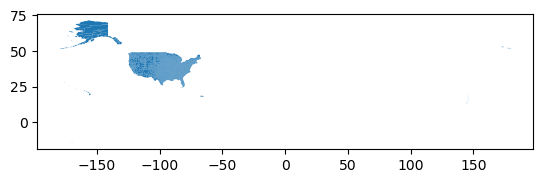

In [74]:
# d View map of counties
counties.plot()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.B. Cleaning

Simplify column names as needed.

In [75]:
# Convert data names to lowercase
counties.columns = counties.columns.str.lower()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.C. Data selection

Select all the counties for the state of New York in a new variable `ny_counties` and plot them (you may need to look at the metadata).

<Axes: >

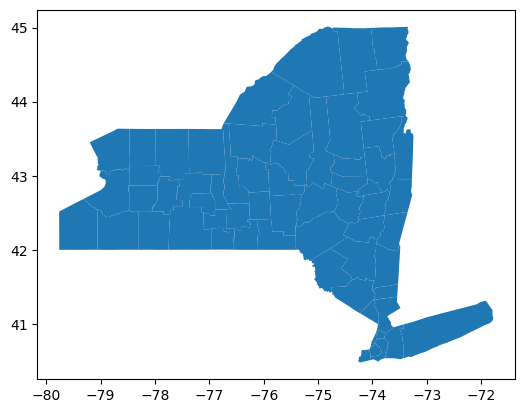

In [76]:
# Subset to New York counties
ny_counties = counties[counties['statefp'] == '36']

# View subsetted New York counties
ny_counties.plot()


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 7 Merging

The goal of this section is to create a single dataframe with the number of spills per county and the corresponding geometries for each county.

### 7.A. Explore data

In the next cells:

a. Print the names of counties in `ny_counties`, without repetition.


In [77]:
# Identify unique counties in county data
print(ny_counties['name'].unique())

['Erie' 'Niagara' 'Jefferson' 'Steuben' 'Seneca' 'Rensselaer' 'Albany'
 'Saratoga' 'Schoharie' 'Schenectady' 'Ulster' 'Dutchess' 'Orange'
 'Columbia' 'Tompkins' 'Tioga' 'Broome' 'Cayuga' 'Genesee' 'Onondaga'
 'Oswego' 'Madison' 'Livingston' 'Monroe' 'Ontario' 'Orleans' 'Wayne'
 'Chautauqua' 'Sullivan' 'Chemung' 'Cattaraugus' 'Fulton' 'Montgomery'
 'Cortland' 'Warren' 'Washington' 'Otsego' 'Queens' 'Bronx' 'Nassau'
 'Westchester' 'Richmond' 'Kings' 'Suffolk' 'Rockland' 'New York' 'Putnam'
 'Clinton' 'St. Lawrence' 'Herkimer' 'Oneida' 'Yates' 'Greene' 'Schuyler'
 'Delaware' 'Hamilton' 'Lewis' 'Allegany' 'Chenango' 'Wyoming' 'Franklin'
 'Essex']


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Print the names of counties in `spills_per_county`, without repetition. Examine the differences in the outputs.

In [78]:
# Print unique counties in summarized spill data
print(spills_per_county['county'].unique())

['Albany' 'Allegany' 'Bronx' 'Broome' 'Cattaraugus' 'Cayuga' 'Chautauqua'
 'Chemung' 'Chenango' 'Clinton' 'Columbia' 'Cortland' 'Delaware'
 'Dutchess' 'Erie' 'Essex' 'Franklin' 'Fulton' 'Genesee' 'Greene'
 'Hamilton' 'Herkimer' 'Jefferson' 'Kings' 'Lewis' 'Livingston' 'Madison'
 'Monroe' 'Montgomery' 'Nassau' 'New Jersey - Region 2' 'New York'
 'Niagara' 'Oneida' 'Onondaga' 'Onondaga Indian Reservation' 'Ontario'
 'Orange' 'Orleans' 'Oswego' 'Otsego' 'Pennsylvania - Region 3' 'Putnam'
 'Queens' 'Rensselaer' 'Richmond' 'Rockland' 'Saratoga' 'Schenectady'
 'Schoharie' 'Schuyler' 'Seneca' 'St Lawrence' 'Steuben' 'Suffolk'
 'Sullivan' 'Tioga' 'Tompkins' 'Tuscarora Indian Reservation' 'Ulster'
 'Warren' 'Washington' 'Wayne' 'Westchester' 'Wyoming' 'Yates']


<!-- END QUESTION -->



c. Which are the county names that are in `spills_per_county`, but not in `ny_counties`? Your answer should be a list of strings
HINT: You can use the `numpy` function [`setdiff1d()`](https://numpy.org/doc/stable/reference/generated/numpy.setdiff1d.html), pay attention to the example in the documentation. Store your answer in the `diff_names` variable. 


In [79]:
# Identify which counties are listed in the summarized spills but do not have a corresponding geometry in county data
diff_names_spills = np.setdiff1d(spills_per_county['county'].unique(), ny_counties['name'].unique())
diff_names_spills


array(['New Jersey - Region 2', 'Onondaga Indian Reservation',
       'Pennsylvania - Region 3', 'St Lawrence',
       'Tuscarora Indian Reservation'], dtype=object)

In [80]:
grader.check("7Ac")

7Ac results: All test cases passed!

d. Which are the county names that are in `ny_counties`, but not in `spills_per_county`? Your answer should be a list of a string/strings.


In [81]:
#Identify counties with gemoetries in county data, but do not have spill data
diff_names_ny = np.setdiff1d(ny_counties['name'].unique(), spills_per_county['county'].unique())
diff_names_ny

array(['St. Lawrence'], dtype=object)

In [82]:
grader.check("7Ad")

7Ad results: All test cases passed!

e. What is the number of spills in 'Tuscarora Indian Reservation' and in 'Onondaga Indian Reservation'?


In [83]:
# e. Identify number of spills in the Tuscarora reservation and the Onodaga reservation 
print(f"Number of spills in Tuscarora Indian Reservation: ", spills_per_county.set_index('county').loc['Tuscarora Indian Reservation', 'n_spills'])

print(f"Number of spills in Onondaga Indian Reservation: ", spills_per_county.set_index('county').loc["Onondaga Indian Reservation",'n_spills'])

Number of spills in Tuscarora Indian Reservation:  2
Number of spills in Onondaga Indian Reservation:  1


### 7.B. Data updates

In the next cell, update 'St Lawrence' to 'St. Lawrence' in the `spills_per_county` data frame. Verify the update was successful with an assert test. 


In [84]:
# Correct puncutation of St. Lawrence County in spills summary data
spills_per_county['county'] = spills_per_county['county'].str.replace("St Lawrence", "St. Lawrence")

# Confirm update
assert "St. Lawrence" in spills_per_county['county'].values, "St. Lawrence values not updated successfully"

### 7.C. Merge

In the following cells:

a. Use this cell to make any other updates needed for making an inner join of the `spills_per_county` and `ny_counties`. HINT: [`pd.merge`](https://pandas.pydata.org/pandas-docs/version/2.3/reference/api/pandas.merge.html)


In [85]:
# a. Make the name of the column holding county names consistent between both dataframes (it will be the join key)
ny_counties = ny_counties.rename(columns = {'name' :'county'})

b. Store the inner join of the `spills_per_county` and `ny_counties` dataframes in a new variable named `ny_spills`.


In [86]:
# Join county gemoteries and spill data
ny_spills = ny_counties.merge(right = spills_per_county, on="county", how = 'inner')

In [87]:
# View joined data
ny_spills

,statefp,countyfp,countyns,geoid,geoidfq,county,namelsad,lsad,classfp,mtfcc,csafp,cbsafp,metdivfp,funcstat,aland,awater,intptlat,intptlon,geometry,n_spills
0,36,029,00974113,36029,0500000US36029,Erie,Erie County,06,H1,G4020,160,15380,None,A,2700743371,476876406,+42.7527590,-078.7781922,"POLYGON ((-78.77760 42.46188, -78.77756 42.461...",320
1,36,063,00974130,36063,0500000US36063,Niagara,Niagara County,06,H1,G4020,160,15380,None,A,1352876142,1598772310,+43.2726719,-078.8129431,"POLYGON ((-78.49165 43.08396, -78.49179 43.084...",97
2,36,045,00974121,36045,0500000US36045,Jefferson,Jefferson County,06,H1,G4020,None,48060,None,A,3283928401,1524534721,+43.9963890,-076.0529678,"POLYGON ((-75.90417 43.69796, -75.90437 43.697...",114
3,36,101,00974148,36101,0500000US36101,Steuben,Steuben County,06,H1,G4020,236,18500,None,A,3601403364,35034920,+42.2667252,-077.3855253,"POLYGON ((-77.08327 42.00002, -77.09391 41.999...",77
4,36,099,00974147,36099,0500000US36099,Seneca,Seneca County,06,H1,G4020,464,42900,None,A,838377561,172813845,+42.7822943,-076.8270880,"POLYGON ((-76.96393 43.01284, -76.96393 43.012...",27
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57,36,003,00974100,36003,0500000US36003,Allegany,Allegany County,06,H1,G4020,None,None,None,A,2666410162,12989705,+42.2478532,-078.0261531,"POLYGON ((-78.04342 42.51846, -78.04326 42.518...",32
58,36,017,00974107,36017,0500000US36017,Chenango,Chenango County,06,H1,G4020,None,None,None,A,2314006867,13433903,+42.4780238,-075.6022407,"POLYGON ((-75.40346 42.50870, -75.40331 42.508...",44
59,36,121,00974158,36121,0500000US36121,Wyoming,Wyoming County,06,H1,G4020,None,None,None,A,1535086368,9085227,+42.7013652,-078.2285762,"POLYGON ((-77.95538 42.71354, -77.95537 42.713...",27
60,36,033,00974115,36033,0500000US36033,Franklin,Franklin County,06,H1,G4020,None,None,None,A,4219867377,176612003,+44.5943758,-074.3106700,"POLYGON ((-74.38487 44.11157, -74.38667 44.111...",55


<!-- BEGIN QUESTION -->

c. An inner join only keeps the rows whose `county` appears in both dataframes, and it does not warn you about the rows it drops. Which records from `spills_per_county` were dropped by the inner join, and how many spills did each one have? Add the cells you need to find the dropped records.

In [88]:
#Compare lengths of `ny_spills` and `spills_per_county` to identify dropped rows
print(f"ny_spills has {len(ny_spills)} counties")
print(f"spills_per_county has {len(spills_per_county)} counties")

ny_spills has 62 counties
spills_per_county has 66 counties


In [89]:
# Identify counties/regions that were dropped and the number of spills in each
spills_per_county[~spills_per_county['county'].isin(ny_spills['county'])]


,county,n_spills
30,New Jersey - Region 2,7
35,Onondaga Indian Reservation,1
41,Pennsylvania - Region 3,1
58,Tuscarora Indian Reservation,2


Records from New Jersey = Region 2, Pennsylvannia - Region 3, Onondaga Indian Reservation, and Tuscarora Indian Reservation.  There were 7 spills in New Jersey - Region 2, 1 in Pennsylvannia - Regions 3, 1 in Onondaga Indian Reservation, and 2 in Tuscarora Indian Reservation.

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Does dropping these records affect the map or the information we will report? Write your answer in the following markdown cell.

Dropping the New Jersey and Pennsylvannia regions will not affect the information we will report because they are outside of New York.  However, dropping records from the Indian reservations will drop data from the counties they are in, and will underepresent the environmental hazards in those communities.

<!-- END QUESTION -->


From our previous exploration we know that Tuscarora Indian Reservation and Onondaga Indian Reservation will not be in the join. Tuscarora Indian Reservation is located within Niagara county and Onondaga Indian Reservation is located within Onondaga county. 

e. Since the reservations do not appear in the `ny_counties` dataframe, add the Tuscarora Indian Reservation spills to Niagara county and the Onondaga Indian Reservation spills to Onondaga county in `ny_spills`. We will add a note about this in our final map, and we will reflect on this choice in exercise 8.b. Add the cells you need to make this update **and** verify that the dataframe was updated.

In [90]:
# Identify number of spills in Niagara and Onondaga counties excluding the Indian Reservations
ny_spills[ny_spills['county'].isin(['Niagara', 'Onondaga'])]

,statefp,countyfp,countyns,geoid,geoidfq,county,namelsad,lsad,classfp,mtfcc,csafp,cbsafp,metdivfp,funcstat,aland,awater,intptlat,intptlon,geometry,n_spills
1,36,063,00974130,36063,0500000US36063,Niagara,Niagara County,06,H1,G4020,160,15380,None,A,1352876142,1598772310,+43.2726719,-078.8129431,"POLYGON ((-78.49165 43.08396, -78.49179 43.084...",97
19,36,067,00974132,36067,0500000US36067,Onondaga,Onondaga County,06,H1,G4020,532,45060,None,A,2016027811,70512841,+43.0065163,-076.1961336,"POLYGON ((-76.08017 42.78160, -76.08018 42.780...",214


In [91]:
# Add Tuscarora Indian Reservation spills to Niagara
ny_spills.loc[ny_spills['county'] == 'Niagara', 'n_spills'] = ny_spills.loc[ny_spills['county'] == 'Niagara', 'n_spills'] + 2

In [92]:
# Add Onondaga Indian Reservation spills to Onondaga
ny_spills.loc[ny_spills['county'] == 'Onondaga', 'n_spills'] = ny_spills.loc[ny_spills['county'] == 'Onondaga', 'n_spills'] + 1

In [93]:
# Confirm changes
assert ny_spills.set_index('county').loc['Niagara', 'n_spills'] == 99, "Tuscarora reservations skills failed to add to Niagara county"

assert ny_spills.set_index('county').loc['Onondaga', 'n_spills'] == 215, "Tuscarora reservations skills failed to add to Niagara county"

## 8. Map
a. Create a choropleth map of the number of petroleum spills per county in the state of New York in 2023. 
Your map should be polished and have (at least) the following updates:
- a legend indicating the number of spills
- an updated color map
- a title 
- no axis
- an annotation with the data source (New York State Department of Environmental Conservation) and date of access



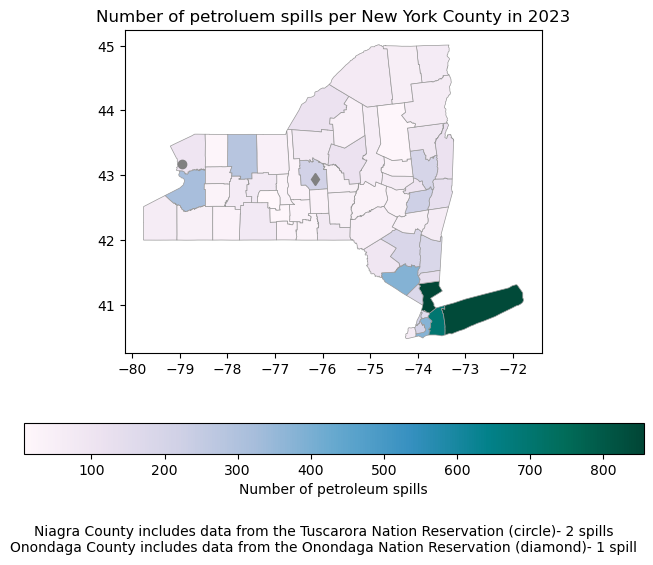

In [94]:
# Map number of spills per New York county in 2023

fig, ax = plt.subplots(figsize = (8,6))

# ax.axis('off')
ny_spills.plot(ax =ax,
               column = 'n_spills',
               legend = True,
               edgecolor="0.6",
               linewidth=0.5,
               cmap = 'PuBuGn',
               legend_kwds ={
               "label" : "Number of petroleum spills",
               "orientation": "horizontal"
                      })
ax.set_title("Number of petroluem spills per New York County in 2023")
fig.text(0.5, 0.01, 
         'Niagra County includes data from the Tuscarora Nation Reservation (circle)- 2 spills\nOnondaga County includes data from the Onondaga Nation Reservation (diamond)- 1 spill', 
         ha='center')
ax.plot(-76.1558, 42.9419, marker = 'd', color = 'grey') # Add a point to indicate the Onondaga Nation Reservation
ax.plot(-78.9572, 43.1664, marker = 'o', color = 'grey') # Add a point to indicate the Tuscarora Nation Reservation

plt.show();


b. Write a description of how the map was created, including key takeaways. If you need to do additional data analysis to include relevant information from the data, you may include additional cells here.

In your description, also reflect on how we handled the spills reported in the Tuscarora and Onondaga Indian Reservations (exercise 7.C.e) in terms of data governance and the CARE Principles for Indigenous Data Governance from Task 1.

A map of the number of petroleum spills per each New York county was created by summarizing reported petroleum spill incidents by each county in the State of New York. Spills were included if their reported spill date occurred in 2023. Spills were matched to counties by reported location county name. Spills from the Tuscarora Reservation and Onongdaga Reservation were added to the total spill count of their respective surrounding counties of Niagara and Onondaga. Information on spill incidents was obtained from the New York State Department of Environmental Conservation's [Spill Incident dataset](https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk/about_data). County boundaries are based on the [2026 TIGER/Line Shapefiles](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html) by the United States Census Bureau. Mapping indicates that counties on or near Long Island experienced the most petroleum spill incidents in 2023, with over 800 spills in two of the counties.  Most counties in the state experienced at least 100 spill incidents.

Data regarding spill incidents reported in the territories held by the Tuscarora Nation of New York and Onondaga Nation were handled according to the CARE Principles for Indigenous Data Governance.  Spill incidents from their respective territories were purposefully included to ensure that the analysis is relevant and beneficial to the two nations.  Spill incidents from their territories are cited to recognize the sovereignty of the indigenous nations over data collected in their territories and pertaining to their members.  However, the Tuscarora Nation of New York, the Onodaga Nation, and the State of New York were not directly consulted for this analysis outside of their data provided in publicly-accessible datasets.


## Complete workflow

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the choropleth map of the number of petroleum spills per county in the state of New York in 2023. The only output of this cell should be the choropleth map  you produced in the previous exercise. Further guidance on what to include in this final workflow is in the assignment rubric.